In [1]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.markers as mmarkers
from matplotlib.patches import Patch
import seaborn as sns
import scipy

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Avenir'

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KONKLE_LOCALIZER_DIR = paths.KONKLE_LOCALIZER_DIR
KANWISHER_LOCALIZER_DIR = paths.KANWISHER_LOCALIZER_DIR

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


# Supplementary:  NSD-Synthetic: Subject-Subject vs. Model-Subject

In [5]:
tthreshold = 7
randommodel_tthreshold = 3
frois = ['FFA', 'EBA', 'PPA']
model_localizer = 'grillspector'

ALL_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsdsynthetic.csv'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_brain_optimized_model_names = ma.get_model_names(model_type='brain_optimized')
all_random_model_names = ma.get_model_names(model_type='random')


pearsonr
FFA
EBA
PPA

rdmr
FFA
EBA
PPA


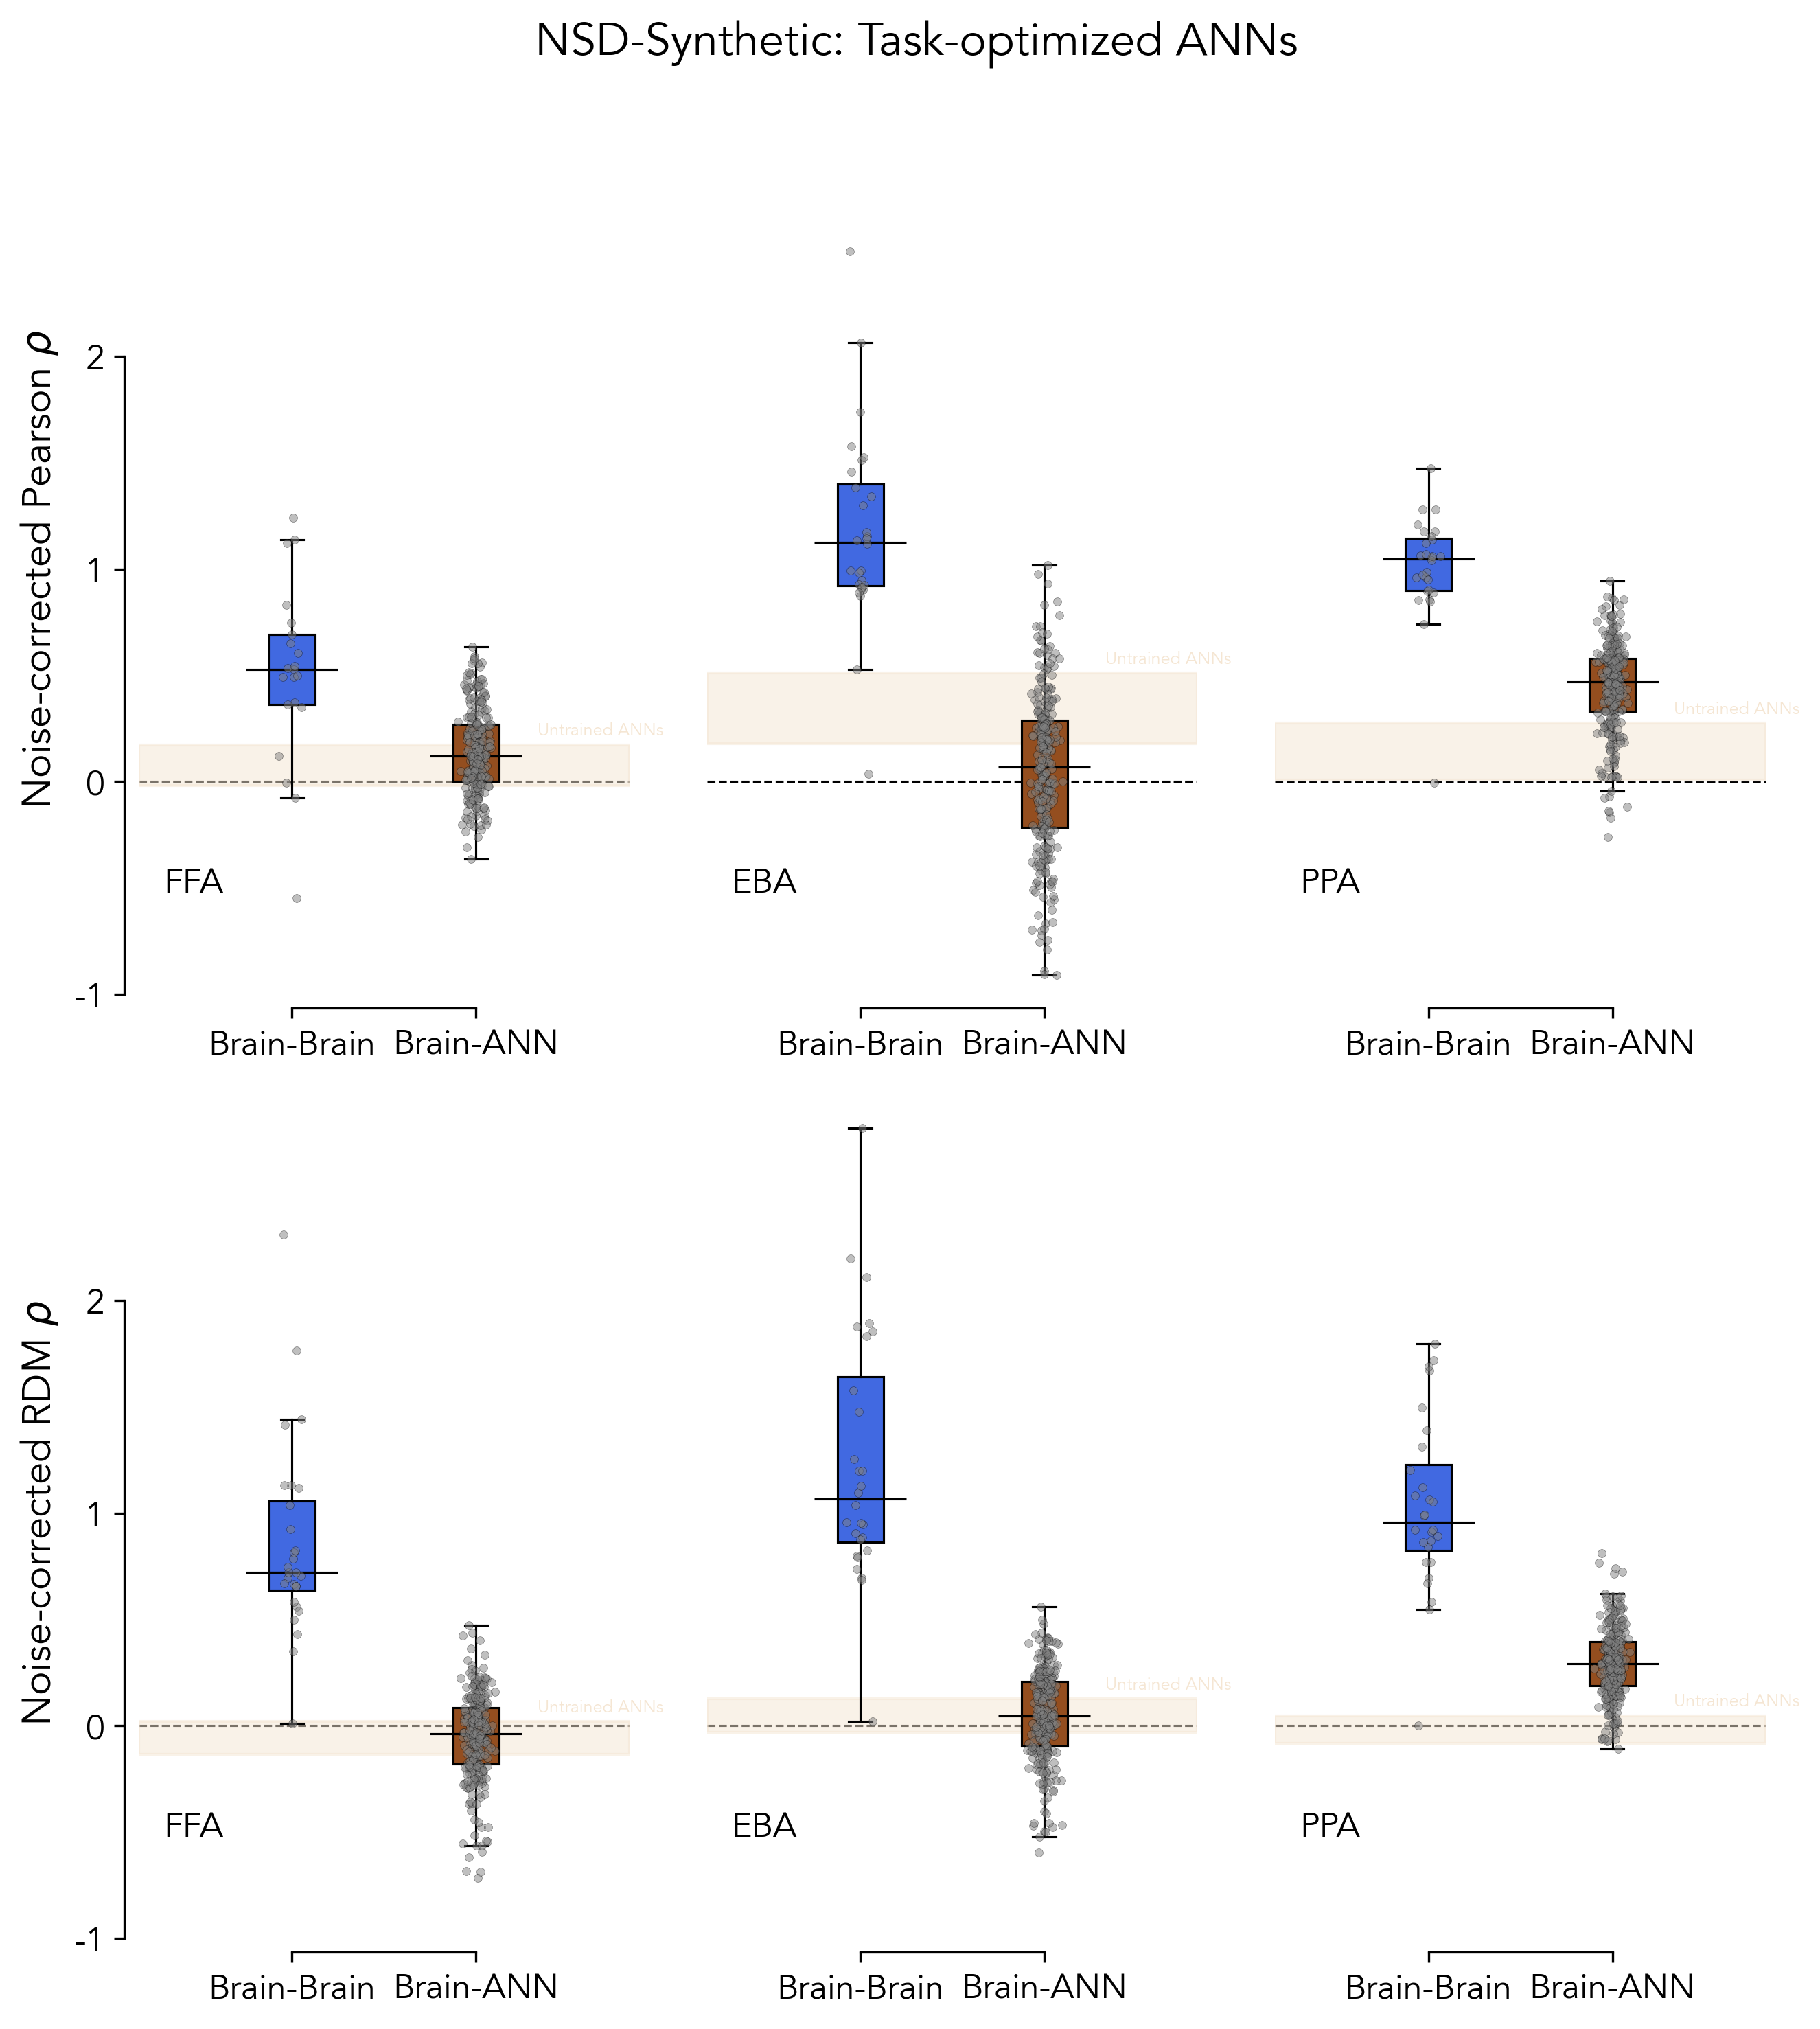

In [18]:
all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_brain_optimized_model_names = ma.get_model_names(model_type='brain_optimized')
all_random_model_names = ma.get_model_names(model_type='random')

savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

all_correlations_csv = pd.read_csv(ALL_CORRELATIONS_CSV_PATH)

humans = []
human_rows = all_correlations_csv[
    (all_correlations_csv['system1_type'] == 'human') |
    (all_correlations_csv['system2_type'] == 'human')
]
for idx, row in human_rows.iterrows():
    if row['system1_type'] == 'human':
        humans.append(int(row['system1'].split('_')[1]))
    if row['system2_type'] == 'human':
        humans.append(int(row['system2'].split('_')[1]))
humans = np.unique(humans)

models = []
model_rows = all_correlations_csv[
    (all_correlations_csv['system1_type'] == 'model') |
    (all_correlations_csv['system2_type'] == 'model')
]
for idx, row in model_rows.iterrows():
    if row['system1_type'] == 'model':
        models.append((row['system1']).split('_')[1])
    if row['system2_type'] == 'model':
        models.append((row['system2']).split('_')[1])
models = np.unique(models)

taskoptimized_models = [model for model in models if model in all_task_optimized_model_names]
random_models = [model for model in models if model in all_random_model_names]

# Colors
human_color = '#4169e1' # Royal blue
to_model_color = '#944e1f' # Brown
random_model_color = '#f5e6d3' # Very light brown

metrics = ['pearsonr', 'rdmr']
metric_norm_type = 'normed' # 'normed' or 'raw'
lims_dict = {
    'pearsonr': (-1, 3),
    'rdmr': (-1, 3)
}
ticks_dict = {
    'pearsonr': [-1, 0, 1, 2],
    'rdmr': [-1, 0, 1, 2]
}

fig, axes = plt.subplots(len(metrics), len(frois), figsize=(3*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    print()
    print(metric)
    for fidx, froi in enumerate(frois):
        if len(frois) == 1:
            ax = axes[midx]
        else:
            ax = axes[midx, fidx]
        print(froi)
        
        # Get human-human correlations
        hh_corrs = np.array(all_correlations_csv[
            (((all_correlations_csv['system1_type'] == 'human') & (all_correlations_csv['system2_type'] == 'human'))) &
            (((all_correlations_csv['system1_froi'] == froi) & (all_correlations_csv['system2_froi'] == froi))) &
            (all_correlations_csv['metric_type'] == metric)
        ][f'metric_{metric_norm_type}']).flatten()
        # Ignore NaNs
        hh_corrs = hh_corrs[~np.isnan(hh_corrs)]

        # Get human-model correlations
        all_moh_rows = all_correlations_csv[
            (((all_correlations_csv['system1_type'] == 'human') & (all_correlations_csv['system2_type'] == 'model')) |
             ((all_correlations_csv['system1_type'] == 'model') & (all_correlations_csv['system2_type'] == 'human'))) &
            (((all_correlations_csv['system1_froi'] == froi) & (all_correlations_csv['system2_froi'] == froi))) &
            (all_correlations_csv['metric_type'] == metric)
        ]
        
        to_moh_corrs = []
        for idx, row in all_moh_rows.iterrows():
            if row['system1_type'] == 'model':
                model_name = row['system1'].split('_')[1]
            else:
                model_name = row['system2'].split('_')[1]
            if model_name in taskoptimized_models:
                to_moh_corrs.append(row[f'metric_{metric_norm_type}'])
        to_moh_corrs = np.array(to_moh_corrs).flatten()
        # Ignore NaNs
        to_moh_corrs = to_moh_corrs[~np.isnan(to_moh_corrs)]
        
        random_moh_corrs = []
        for idx, row in all_moh_rows.iterrows():
            if row['system1_type'] == 'model':
                model_name = row['system1'].split('_')[1]
            else:
                model_name = row['system2'].split('_')[1]
            if model_name in random_models:
                random_moh_corrs.append(row[f'metric_{metric_norm_type}'])
        random_moh_corrs = np.array(random_moh_corrs).flatten()
        # Ignore NaNs
        random_moh_corrs = random_moh_corrs[~np.isnan(random_moh_corrs)]

        # Define positions
        human_x = 0
        box_offset = 0.15
        barwidth = 0.075
        linewidth = 0.75
        jitter_scale = 0.01
        markersize = 8
        alpha = 0.5
        plottext_fontsize = 6
        medianlineextra = 0.075

        # y=0 line
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Shaded area for random models (floor)
        if len(random_moh_corrs) > 0:
            hr_q1 = np.percentile(random_moh_corrs, 25)
            hr_q3 = np.percentile(random_moh_corrs, 75)
            ax.axhspan(hr_q1, hr_q3, color=random_model_color, alpha=0.5, zorder=1)
            ax.text(0.25, hr_q3 + 0.02, 'Untrained ANNs', color=random_model_color,
                    fontsize=plottext_fontsize, verticalalignment='bottom')

        # Boxplots for human group: human-human and model-human
        human_box_positions = [human_x - box_offset, human_x + box_offset]
        human_box_data = [hh_corrs, to_moh_corrs]
        human_colors = [human_color, to_model_color]

        boxes_human = ax.boxplot(
            human_box_data, positions=human_box_positions, patch_artist=True,
            widths=barwidth, showfliers=False,
            boxprops={'color': 'black', 'linewidth': linewidth},
            whiskerprops=dict(linewidth=linewidth),
            capprops=dict(linewidth=linewidth),
            medianprops={'color': 'black', 'linewidth': linewidth},
            flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
        )
        for box, color in zip(boxes_human['boxes'], human_colors):
            box.set(facecolor=color)

        # Scatter points for human group
        for i, (data, pos) in enumerate(zip(human_box_data, human_box_positions)):
            if len(data) > 0:
                x_jitter = np.zeros(len(data)) + pos + np.random.normal(0, jitter_scale, len(data))
                ax.scatter(x_jitter, data, color='gray', alpha=alpha, zorder=5,
                          edgecolors=(0, 0, 0), s=markersize, linewidths=0.15)
                med = np.median(data)
                ax.plot([pos - medianlineextra, pos + medianlineextra], [med, med], 
                       color='black', linewidth=linewidth, solid_capstyle='butt')

        # Write froi name in bottom left corner
        ax.text(0.05, 0.15, froi, transform=ax.transAxes, fontsize=12, verticalalignment='top')

        yticks = np.array(ticks_dict[metric])
        ylims = lims_dict[metric]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks, fontsize=12)
        ax.spines['left'].set_bounds(yticks.min(), yticks.max())
        ax.set_ylim(ylims)
        ax.spines['bottom'].set_bounds(human_x - box_offset, human_x + box_offset)
        ax.set_xlim(human_x - 0.4, human_x + 0.4)
        # ax.set_xlabel('Probe group', fontsize=14)

        if fidx != 0:
            ax.spines['left'].set_visible(False)
            ax.yaxis.set_ticks([])
        else:
            prefix = ''
            if metric_norm_type == 'normed':
                prefix = 'Noise-corrected '
            if metric == 'pearsonr':
                ax.set_ylabel(prefix + r'Pearson $\rho$', fontsize=14)
            else:
                ax.set_ylabel(prefix + r'RDM $\rho$', fontsize=14)

        ax.set_xticks([human_x - box_offset, human_x + box_offset], ['Brain-Brain', 'Brain-ANN'], fontsize=12)

plt.tight_layout()
plt.suptitle('NSD-Synthetic: Task-optimized ANNs', fontsize=16)
plt.subplots_adjust(top=0.92)

if savefig:
    plt.savefig(f'{plot_dir}/fig3_sup_otherfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()
